# Predicting Game Completion Time Across Story, Side Content and 100% Completion
**Multi-Output Regression on HowLongToBeat Data**
Statistical Inference, Central Limit Theorem, Hypothesis Testing, and Machine Learning Models based on Coursework Curriculum (Labs 4, 5, 6, 8).


In [75]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score
sns.set_theme(style='whitegrid')

TARGETS = ['main_story', 'main_plus_sides', 'completionist']
MIN_POLLED = 5   # minimum number of player submissions per time (reduces noise)
alpha = 0.05     # significance level for hypothesis testing (from Lab 5 & 6)


## 1. Load, Inspect and Clean Dataset
Dataset inspection and cleaning practices strictly following **Lab 8 Part C**:
- Displaying first & last 5 rows, shape, columns, datatypes, info, missing values, duplicates.


In [76]:
df_raw = pd.read_csv('/Users/krrishparmar/Downloads/archive/hltb_dataset.csv')

print("FIRST 5 ROWS:\n", df_raw.head(5))
print("\nLAST 5 ROWS:\n", df_raw.tail(5))
print("\nSHAPE:", df_raw.shape)
print("\nCOLUMNS:", list(df_raw.columns))
print("\nDATA TYPES:\n", df_raw.dtypes[TARGETS + ['release_year', 'genres', 'platform', 'developer']])
print("\nINFO:")
df_raw.info()
print("\nMISSING VALUES (TARGETS):\n", df_raw[TARGETS].isnull().sum())
print("\nDUPLICATES:", df_raw.duplicated(subset=['name', 'release_year']).sum())

# Cleaning pipeline
df = df_raw[df_raw['type'] == 'game'].copy()
polled = ['main_story_polled', 'main_plus_sides_polled', 'completionist_polled']
df = df.dropna(subset=TARGETS + polled + ['genres', 'release_year'])
df = df[(df[polled].min(axis=1) >= MIN_POLLED)]                 # reliable times only
df = df[(df['release_year'] >= 1980) & (df['release_year'] <= 2026)]
df = df[(df.main_story <= df.main_plus_sides) & (df.main_plus_sides <= df.completionist)]  # logical order
df = df.drop_duplicates(subset=['name', 'release_year']).reset_index(drop=True)

# Cap extreme outliers at the 99th percentile
for t in TARGETS:
    df[t] = df[t].clip(upper=df[t].quantile(0.99))

print('\nClean Dataset Shape:', df.shape)
df[TARGETS].describe()


FIRST 5 ROWS:
    id                           name  type  \
0   1           688(I) Hunter/Killer  game   
1   2           Beyond Good & Evil 2  game   
2  18                  'Splosion Man  game   
3  19    .hack//G.U. Vol. 1: Rebirth  game   
4  20  .hack//G.U. Vol. 2: Reminisce  game   

                                            platform  \
0                                                 PC   
1                                                NaN   
2                                           Xbox 360   
3  Nintendo Switch, PC, PlayStation 2, PlayStation 4   
4  Nintendo Switch, PC, PlayStation 2, PlayStation 4   

                          genres            developer  \
0  Simulation, Strategy/Tactical            Sonalysts   
1              Action, Adventure  Ubisoft Montpellier   
2                         Action  Twisted Pixel Games   
3           Action, Role-Playing        CyberConnect2   
4           Action, Role-Playing        CyberConnect2   

                 publisher r

,main_story,main_plus_sides,completionist
count,7353.000000,7353.000000,7353.000000
mean,11.355846,17.669407,31.551443
std,11.981889,20.278868,43.060883
min,0.020000,0.020000,0.030000
25%,3.480000,5.000000,6.950000
50%,7.210000,10.340000,15.760000
75%,14.230000,21.660000,37.100000
max,60.532000,108.852400,256.891600


## 2. Descriptive Statistics & 95% Confidence Intervals
Derived from **Lab 5** and **Practical 6 Assignment**:
Calculating Mean, Median, Mode, Data Range, Variance, Standard Deviation, IQR (Q3 - Q1), and **95% Confidence Interval for the Population Mean** using `stats.t.interval`.


In [77]:
desc_records = []
for t in TARGETS:
    s = df[t]
    m = s.mean()
    sem = stats.sem(s)
    ci_low, ci_high = stats.t.interval(0.95, len(s) - 1, loc=m, scale=sem)
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    desc_records.append({
        'Target': t,
        'Mean': round(m, 2),
        'Median': round(s.median(), 2),
        'Mode': round(s.mode()[0], 2),
        'Range': round(s.max() - s.min(), 2),
        'Variance': round(s.var(), 2),
        'Std Dev': round(s.std(), 2),
        'IQR': round(q3 - q1, 2),
        '95% CI': f'[{ci_low:.2f}, {ci_high:.2f}]'
    })

pd.DataFrame(desc_records)


,Target,Mean,Median,Mode,Range,Variance,Std Dev,IQR,95% CI
0,main_story,11.36,7.21,60.53,60.51,143.57,11.98,10.75,"[11.08, 11.63]"
1,main_plus_sides,17.67,10.34,108.85,108.83,411.23,20.28,16.66,"[17.21, 18.13]"
2,completionist,31.55,15.76,256.89,256.86,1854.24,43.06,30.15,"[30.57, 32.54]"


## 3. Central Limit Theorem (CLT) & Normal Distribution Analysis
Directly implemented from **Lab 4 (Central Limit Theorem)**:
- **Central Limit Theorem Principle**: Regardless of the underlying population distribution (even if heavily skewed), the sampling distribution of the sample mean approaches a **Normal (Gaussian) Distribution** as sample size $n$ increases ($n \ge 30$).
- **Standard Error of the Mean**: $\text{SE} = \frac{\sigma}{\sqrt{n}}$
- **Normality Validation**: Q-Q Plots comparing raw skewed hours vs log-transformed hours.


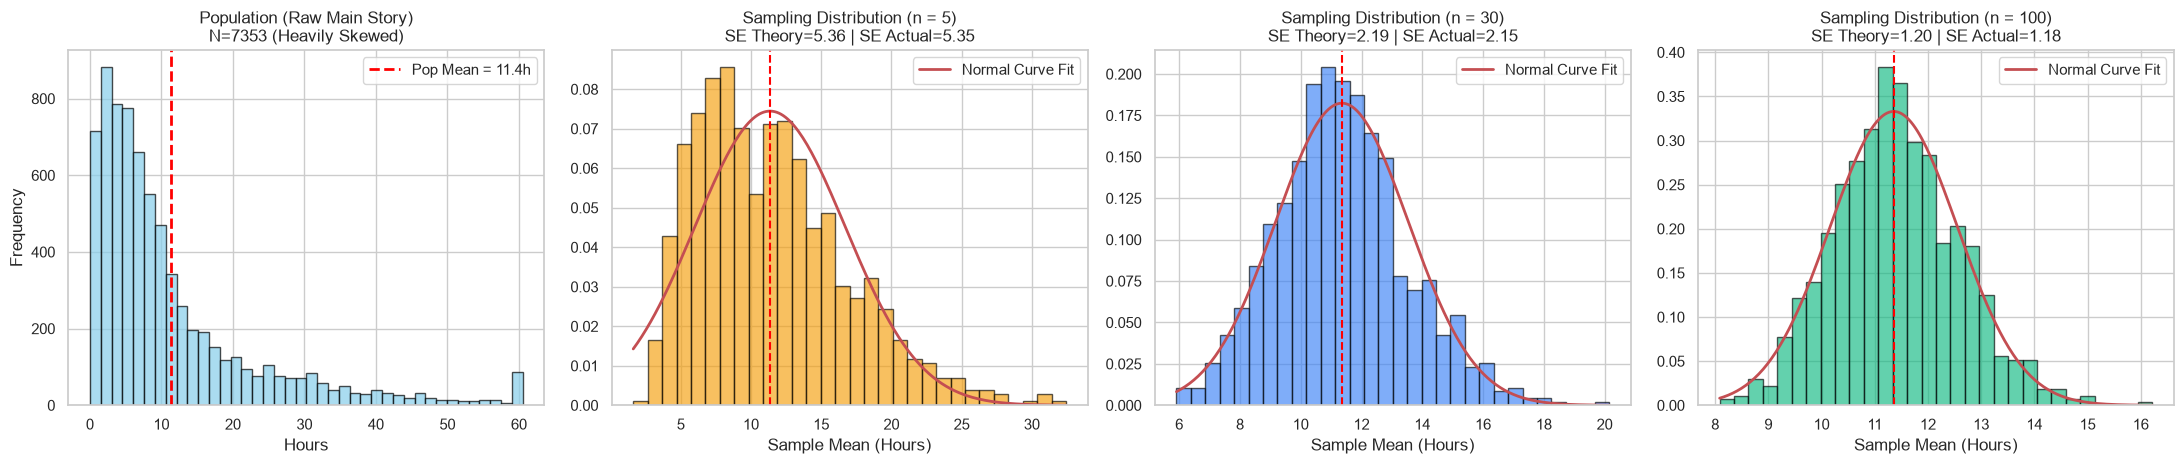

--- CLT Verification Results (Lab 4 style) ---


,Sample Size (n),Population Mean,Estimated Mean,Mean Difference,Theoretical SE,Actual SE
0,5,11.36,11.45,0.090,5.36,5.35
1,30,11.36,11.34,0.013,2.19,2.15
2,100,11.36,11.40,0.041,1.20,1.18


In [78]:
# Central Limit Theorem Demonstration (Lab 4 style)
population = df['main_story'].values
pop_mean = np.mean(population)
pop_std = np.std(population)

sample_sizes = [5, 30, 100]
number_of_samples = 1000

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))

# 1. Population distribution (Right-skewed)
axes[0].hist(population, bins=40, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].axvline(pop_mean, color='red', linestyle='--', linewidth=2, label=f'Pop Mean = {pop_mean:.1f}h')
axes[0].set_title(f'Population (Raw Main Story)\nN={len(population)} (Heavily Skewed)')
axes[0].set_xlabel('Hours')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# 2, 3, 4. Sampling distributions for n = 5, 30, 100
clt_summary = []
colors = ['#f59e0b', '#3b82f6', '#10b981']

for idx, (n, col) in enumerate(zip(sample_sizes, colors), 1):
    np.random.seed(42)
    sample_means = [np.mean(np.random.choice(population, size=n)) for _ in range(number_of_samples)]
    sample_means = np.array(sample_means)
    
    est_mean = np.mean(sample_means)
    actual_se = np.std(sample_means)
    theory_se = pop_std / np.sqrt(n)
    
    # Plot sampling distribution histogram
    axes[idx].hist(sample_means, bins=30, color=col, edgecolor='black', alpha=0.65, density=True)
    
    # Overlay Theoretical Normal PDF Curve N(mu, sigma^2 / n)
    x_axis = np.linspace(min(sample_means), max(sample_means), 200)
    normal_pdf = stats.norm.pdf(x_axis, loc=pop_mean, scale=theory_se)
    axes[idx].plot(x_axis, normal_pdf, 'r-', linewidth=2, label='Normal Curve Fit')
    axes[idx].axvline(pop_mean, color='red', linestyle='--', linewidth=1.5)
    
    axes[idx].set_title(f'Sampling Distribution (n = {n})\nSE Theory={theory_se:.2f} | SE Actual={actual_se:.2f}')
    axes[idx].set_xlabel('Sample Mean (Hours)')
    axes[idx].legend()
    
    clt_summary.append({
        'Sample Size (n)': n,
        'Population Mean': round(pop_mean, 2),
        'Estimated Mean': round(est_mean, 2),
        'Mean Difference': round(abs(pop_mean - est_mean), 3),
        'Theoretical SE': round(theory_se, 2),
        'Actual SE': round(actual_se, 2)
    })

plt.tight_layout()
plt.show()

print("--- CLT Verification Results (Lab 4 style) ---")
display(pd.DataFrame(clt_summary))


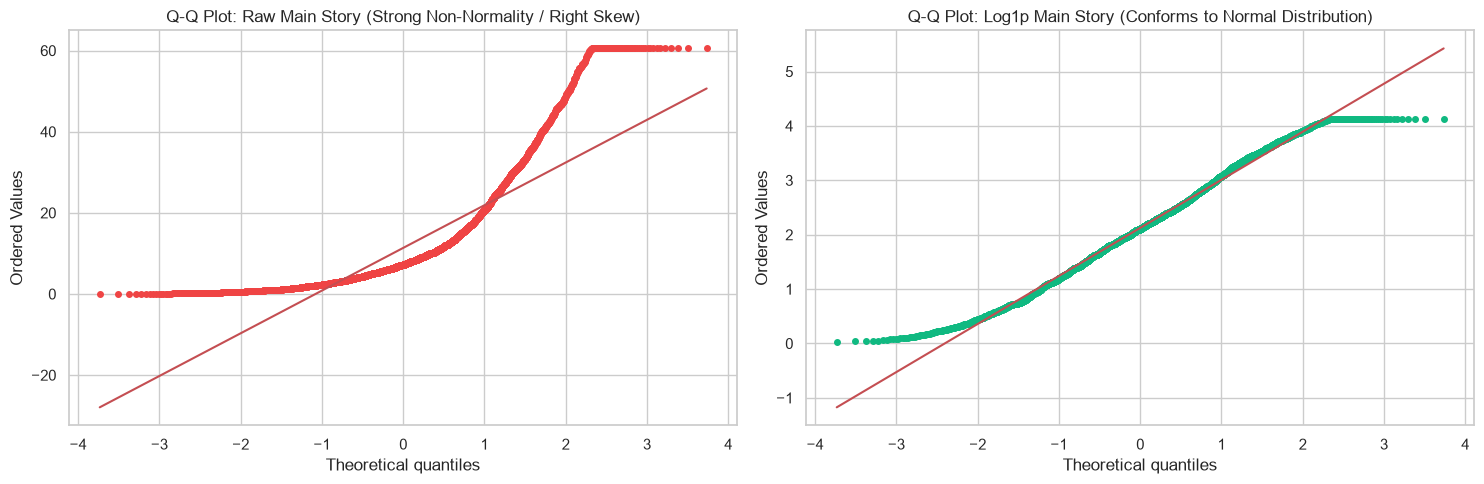

Skewness before log-transform: 1.99 (heavily right-skewed)
Skewness after log-transform : 0.08 (normal bell curve)


In [79]:
# Normal Distribution & Q-Q Plot Analysis (Lab 4 & Lab 5 style)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Q-Q plot for Raw Main Story
stats.probplot(df['main_story'], dist='norm', plot=axes[0])
axes[0].set_title('Q-Q Plot: Raw Main Story (Strong Non-Normality / Right Skew)')
axes[0].get_lines()[0].set_color('#ef4444')
axes[0].get_lines()[0].set_markersize(4)

# Q-Q plot for Log1p Main Story
stats.probplot(np.log1p(df['main_story']), dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot: Log1p Main Story (Conforms to Normal Distribution)')
axes[1].get_lines()[0].set_color('#10b981')
axes[1].get_lines()[0].set_markersize(4)

plt.tight_layout()
plt.show()

raw_skew = stats.skew(df['main_story'])
log_skew = stats.skew(np.log1p(df['main_story']))
print(f"Skewness before log-transform: {raw_skew:.2f} (heavily right-skewed)")
print(f"Skewness after log-transform : {log_skew:.2f} (normal bell curve)")


## 4. Exploratory Data Analysis & Visualizations
Histograms and Boxplots following **Lab 8 Part C** (`df.hist()`, `sns.boxplot()`) and **Practical 6**.


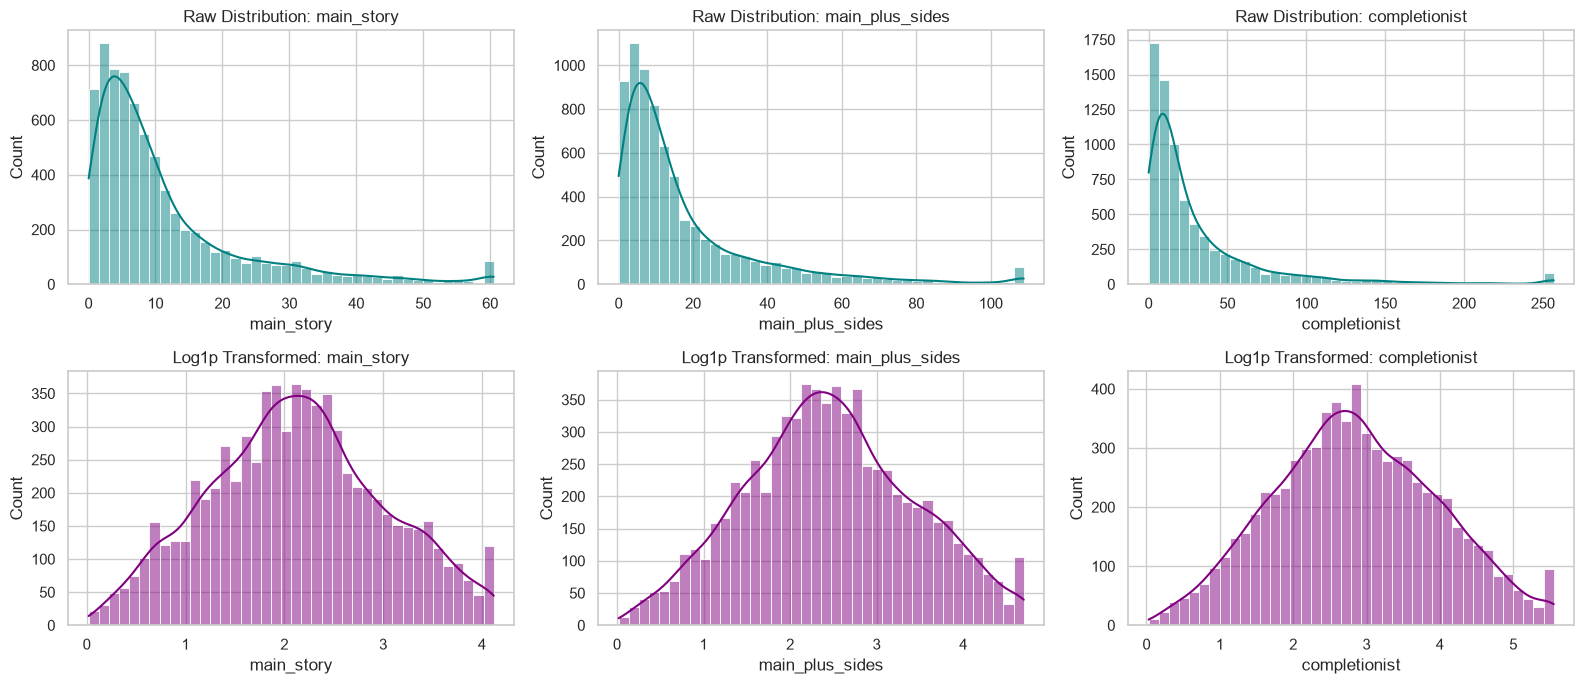

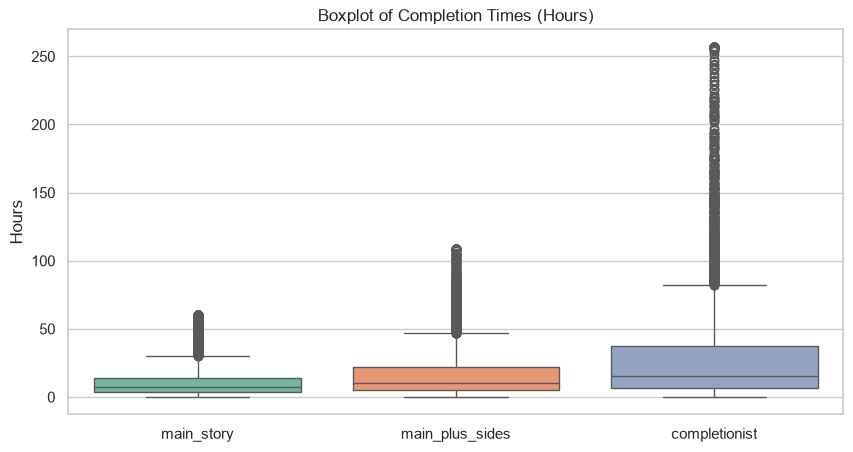

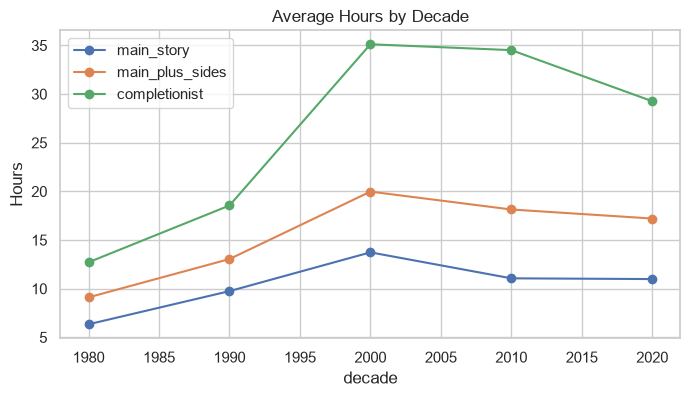

In [80]:
# Histograms for Raw vs Log-transformed targets (Lab 8 style)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, t in enumerate(TARGETS):
    sns.histplot(df[t], bins=40, kde=True, ax=axes[0, i], color='teal')
    axes[0, i].set_title(f'Raw Distribution: {t}')
    sns.histplot(np.log1p(df[t]), bins=40, kde=True, ax=axes[1, i], color='purple')
    axes[1, i].set_title(f'Log1p Transformed: {t}')
plt.tight_layout()
plt.show()

# Boxplots for Targets (Lab 8 style)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[TARGETS], palette='Set2')
plt.title('Boxplot of Completion Times (Hours)')
plt.ylabel('Hours')
plt.show()

# Average hours by release decade
df['decade'] = (df.release_year // 10 * 10).astype(int)
df.groupby('decade')[TARGETS].mean().plot(marker='o', figsize=(8, 4), title='Average Hours by Decade')
plt.ylabel('Hours')
plt.show()


## 5. Correlation, Covariance & Hypothesis Testing
Derived from **Lab 8 Part C** and **Practical 6 (B&C)**:
- **Correlation Matrix** (`df.corr()`)
- **Covariance Matrix** (`df.cov()`)
- **Pearson & Spearman correlation with significance check** (`stats.pearsonr`, `stats.spearmanr`)
- **Two-Sample Hypothesis Testing (t-test)**: Testing whether Modern games (>= 2015) differ significantly in completion time from Classic games (< 2015).


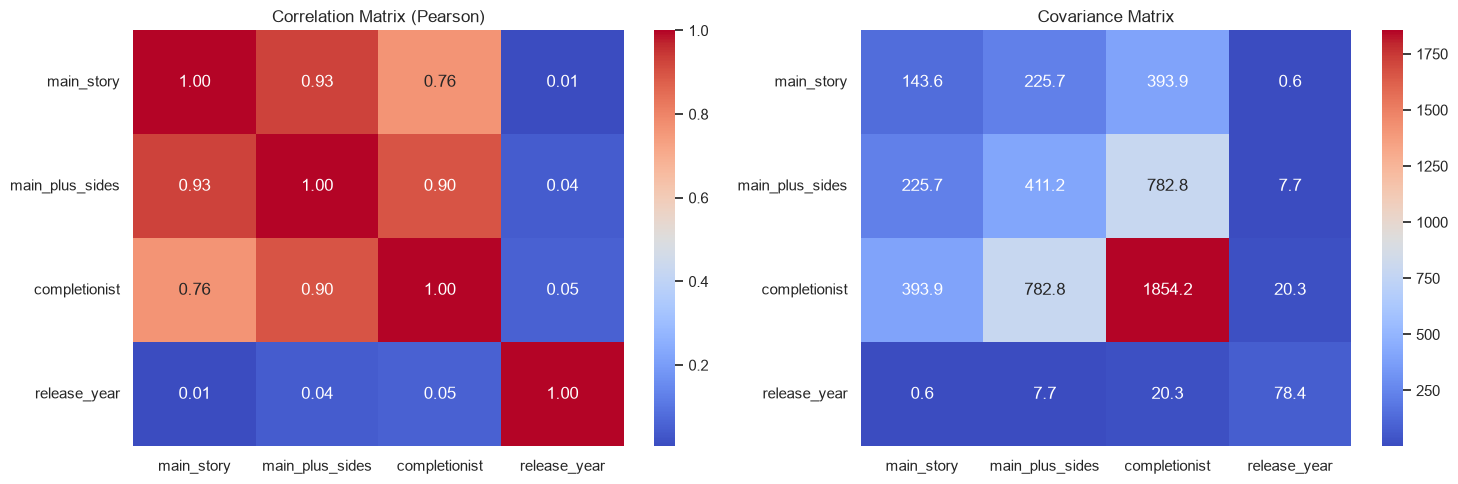

--- Correlation with Release Year & Significance (alpha = 0.05) ---
[main_story]
  Pearson r   : 0.005 | p-value: 6.45e-01 -> Not Significant
  Spearman rho: -0.047 | p-value: 6.07e-05 -> Significant (Reject H0)
[main_plus_sides]
  Pearson r   : 0.043 | p-value: 2.55e-04 -> Significant (Reject H0)
  Spearman rho: -0.039 | p-value: 7.54e-04 -> Significant (Reject H0)
[completionist]
  Pearson r   : 0.053 | p-value: 5.19e-06 -> Significant (Reject H0)
  Spearman rho: -0.026 | p-value: 2.52e-02 -> Significant (Reject H0)

--- Two-Sample t-test: Modern Era (>=2015) vs Classic Era (<2015) ---
H0: Modern Main Story Mean (11.01h) == Classic Main Story Mean (11.75h)
t-statistic: -2.6472
p-value    : 8.13e-03
Decision   : Reject the null hypothesis (Significant difference between eras)


In [81]:
corr_cols = TARGETS + ['release_year']

# Correlation & Covariance Heatmaps (Lab 8 & Practical 6 style)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0])
axes[0].set_title('Correlation Matrix (Pearson)')

sns.heatmap(df[corr_cols].cov(), annot=True, fmt='.1f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Covariance Matrix')
plt.tight_layout()
plt.show()

# Pearson & Spearman correlation significance test vs Release Year (Practical 6 B&C style)
print('--- Correlation with Release Year & Significance (alpha = 0.05) ---')
for t in TARGETS:
    pr, pp = stats.pearsonr(df['release_year'], df[t])
    sr, sp = stats.spearmanr(df['release_year'], df[t])
    print(f'[{t}]')
    print(f'  Pearson r   : {pr:.3f} | p-value: {pp:.2e} -> {"Significant (Reject H0)" if pp < alpha else "Not Significant"}')
    print(f'  Spearman rho: {sr:.3f} | p-value: {sp:.2e} -> {"Significant (Reject H0)" if sp < alpha else "Not Significant"}')

# Two-sample hypothesis test (Lab 5 & Practical 6 style)
print('\n--- Two-Sample t-test: Modern Era (>=2015) vs Classic Era (<2015) ---')
modern = df[df.release_year >= 2015]['main_story']
classic = df[df.release_year < 2015]['main_story']
t_stat, p_val = stats.ttest_ind(modern, classic, equal_var=False)

print(f'H0: Modern Main Story Mean ({modern.mean():.2f}h) == Classic Main Story Mean ({classic.mean():.2f}h)')
print(f't-statistic: {t_stat:.4f}')
print(f'p-value    : {p_val:.2e}')
if p_val < alpha:
    print('Decision   : Reject the null hypothesis (Significant difference between eras)')
else:
    print('Decision   : Fail to reject the null hypothesis')


## 6. Feature Engineering
Features:
- `genres`: Multi-label binarized (`MultiLabelBinarizer`) for genres with >= 50 games
- `platform`: Multi-label binarized (`MultiLabelBinarizer`) for platforms with >= 100 games
- `release_year`, `n_genres`, `n_platforms`, `developer_games`, `has_developer`
- Targets: Log1p transformed Y = log(1 + hours)


In [82]:
def split_list(s): return [x.strip() for x in s.split(',')] if isinstance(s, str) else []

# genres: keep those with >= 50 games
gen_counts = df.genres.apply(split_list).explode().value_counts()
keep_genres = gen_counts[gen_counts >= 50].index.tolist()
mlb_g = MultiLabelBinarizer(classes=keep_genres)
G = pd.DataFrame(mlb_g.fit_transform(df.genres.apply(split_list)), columns=['genre_' + c for c in keep_genres])

# platforms: keep those with >= 100 games
plats = df.platform.fillna('').apply(split_list)
plat_counts = plats.explode().value_counts()
keep_plats = plat_counts[plat_counts >= 100].index.tolist()
mlb_p = MultiLabelBinarizer(classes=keep_plats)
P = pd.DataFrame(mlb_p.fit_transform(plats), columns=['plat_' + c for c in keep_plats])

dev_count = df.developer.map(df.developer.value_counts()).fillna(1)
X = pd.concat([G, P], axis=1)
X['n_genres'] = df.genres.apply(split_list).apply(len)
X['n_platforms'] = plats.apply(len)
X['release_year'] = df.release_year.values
X['developer_games'] = dev_count.values
X['has_developer'] = df.developer.notna().astype(int).values

Y = np.log1p(df[TARGETS])
print('X shape:', X.shape, ' Y shape:', Y.shape)


X shape: (7353, 69)  Y shape: (7353, 3)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/preprocessing/_label.py:1016: UserWarning: unknown class(es) ['2D Action Platformer', '2D Weapon Based Fighting', '3-D', 'Action Adventure', 'Action Role-Playing', 'Action Rpg', 'Action-Adventure', "Arcade/Shoot 'Em Up", 'Art Game', 'Battle Arena', 'Beat-Em-Up', 'Board Game', 'Brawler', 'Breakout', 'Car Combat', 'Card Battle', 'Casual', 'Cinematic Platformer', 'City-Building', 'Combat Flight Simulator', 'Compilation', 'Date Simulation', 'Digital Pet', 'Educational', 'Family', 'Family Games', 'First Person Shooter', 'First-Person Shooter', 'Fitness', 'Flight', 'Flight Combat', 'Fps', 'Full Motion Video (Fmv)', 'Graphic Adventure', 'Incremental', 'Indie', 'Interactive Art', 'Management', 'Massively Multiplayer', 'Maze', 'Multi-Directional Shooter', 'Multidirectional', 'Music', 'Music/Fighting', 'On-Rails', 'Party', 'Pinball', 'Platformer', 'Platforming', 'Point-And-Click Adventure', 'Professional Wres

## 7. Train / Test Split & Machine Learning Models
Strictly trained using the 5 models corresponding to **Lab 8 Part C**:
1. **Ridge (baseline)**: Regularized linear model
2. **Decision Tree**: `DecisionTreeRegressor`
3. **KNN**: `Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])`
4. **Random Forest**: `RandomForestRegressor`
5. **Support Vector Machine (SVR)**: `Pipeline([('scaler', StandardScaler()), ('svr', SVR())])`


In [83]:
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.2, random_state=42)

models = {
    'Ridge (baseline)': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42),
    'KNN': MultiOutputRegressor(
        Pipeline([
            ('scaler', StandardScaler()),
            ('knn', KNeighborsRegressor(n_neighbors=10, weights='distance'))
        ])
    ),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42),
    'SVR': MultiOutputRegressor(
        Pipeline([
            ('scaler', StandardScaler()),
            ('svr', SVR(C=1.0, epsilon=0.1, max_iter=2500))
        ]),
        n_jobs=-1
    ),
}

rows, preds = [], {}
for name, m in models.items():
    print(f'Training {name}...')
    m.fit(Xtr, Ytr)
    p = m.predict(Xte)
    preds[name] = p
    for i, t in enumerate(TARGETS):
        hours_true, hours_pred = np.expm1(Yte.iloc[:, i]), np.expm1(p[:, i])
        rows.append({
            'Model': name,
            'Target': t,
            'MAE (hours)': mean_absolute_error(hours_true, hours_pred),
            'R2 (log scale)': r2_score(Yte.iloc[:, i], p[:, i])
        })

results = pd.DataFrame(rows)
print('Training completed.')


Training Ridge (baseline)...
Training Decision Tree...
Training KNN...
Training Random Forest...
Training SVR...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=2500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=2500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=2500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Training completed.


In [84]:
print('--- MAE in Hours (Lower is Better) ---')
results.pivot(index='Model', columns='Target', values='MAE (hours)')[TARGETS].round(2)


--- MAE in Hours (Lower is Better) ---


Target,main_story,main_plus_sides,completionist
Model,,,
Decision Tree,5.77,9.35,19.05
KNN,5.60,9.14,18.49
Random Forest,5.16,8.36,17.04
Ridge (baseline),5.83,9.56,19.11
SVR,5.20,8.55,17.58


In [85]:
print('--- R2 Score on Log Scale (Higher is Better) ---')
results.pivot(index='Model', columns='Target', values='R2 (log scale)')[TARGETS].round(3)


--- R2 Score on Log Scale (Higher is Better) ---


Target,main_story,main_plus_sides,completionist
Model,,,
Decision Tree,0.349,0.363,0.360
KNN,0.369,0.379,0.376
Random Forest,0.463,0.473,0.476
Ridge (baseline),0.373,0.381,0.393
SVR,0.458,0.467,0.453


Best model: Random Forest


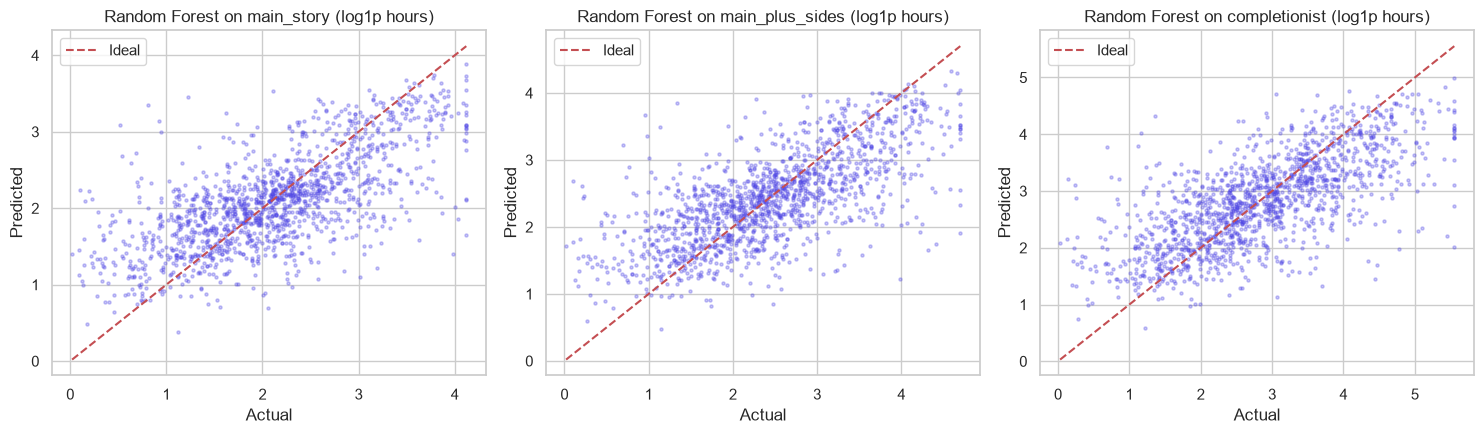

In [86]:
best = results.groupby('Model')['R2 (log scale)'].mean().idxmax()
print('Best model:', best)
p = preds[best]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for i, (a, t) in enumerate(zip(ax, TARGETS)):
    a.scatter(Yte.iloc[:, i], p[:, i], s=5, alpha=0.3, color='#4f46e5')
    lim = [Yte.iloc[:, i].min(), Yte.iloc[:, i].max()]
    a.plot(lim, lim, 'r--', label='Ideal')
    a.set_title(f'{best} on {t} (log1p hours)')
    a.set_xlabel('Actual')
    a.set_ylabel('Predicted')
    a.legend()
plt.tight_layout()
plt.show()


## 8. Feature Importance for Each Target
Shows what drives story time vs. 100% completion time using Random Forest.


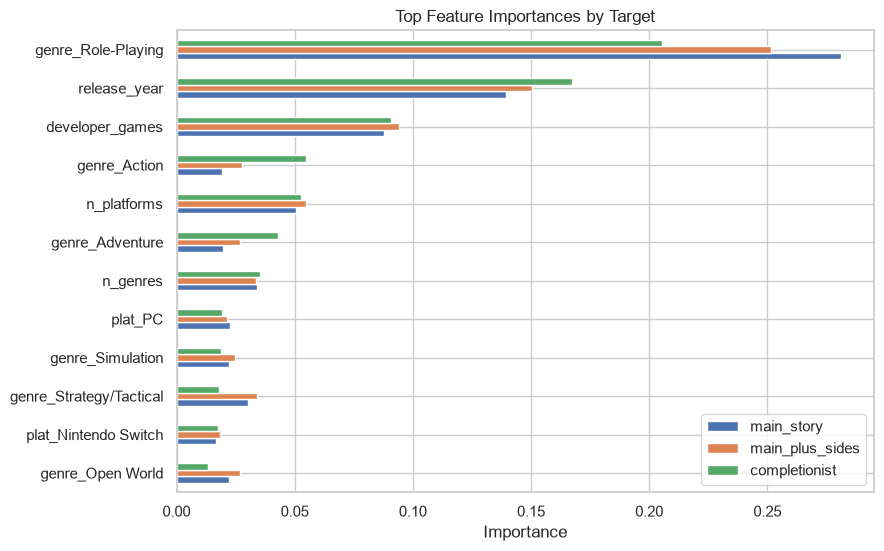

In [87]:
imp = {}
for i, t in enumerate(TARGETS):
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(Xtr, Ytr.iloc[:, i])
    imp[t] = pd.Series(rf.feature_importances_, index=X.columns)
imp = pd.DataFrame(imp)
top_feats = imp.mean(axis=1).sort_values(ascending=False).head(12).index
imp.loc[top_feats].sort_values('completionist').plot(kind='barh', figsize=(9, 6), title='Top Feature Importances by Target')
plt.xlabel('Importance')
plt.show()


## 9. Side-Content Gap by Genre


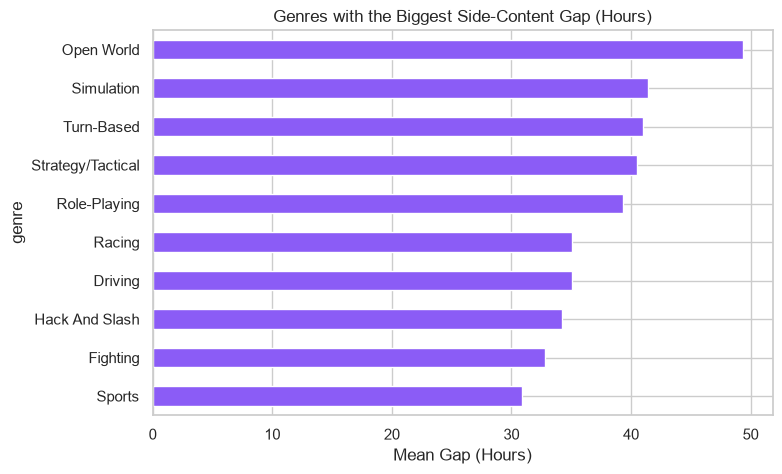

,games,mean_gap,median_ratio
genre,,,
Open World,237,49.38,2.71
Simulation,382,41.46,2.45
Turn-Based,299,41.02,2.00
Strategy/Tactical,263,40.53,2.21
Role-Playing,1356,39.34,2.14
Driving,245,35.06,2.89
Racing,245,35.06,2.89
Hack And Slash,124,34.22,2.55
Fighting,186,32.82,5.26


In [88]:
df['gap'] = df.completionist - df.main_story
df['ratio'] = df.completionist / df.main_story
gg = df.assign(genre=df.genres.str.split(', ')).explode('genre')
gg = gg[gg.genre.isin(keep_genres)]
stats_df = gg.groupby('genre').agg(games=('gap', 'size'), mean_gap=('gap', 'mean'), median_ratio=('ratio', 'median'))
stats_df = stats_df[stats_df.games >= 100].sort_values('mean_gap', ascending=False)
stats_df['mean_gap'].head(10).sort_values().plot(kind='barh', figsize=(8, 5), title='Genres with the Biggest Side-Content Gap (Hours)', color='#8b5cf6')
plt.xlabel('Mean Gap (Hours)')
plt.show()
stats_df.head(10).round(2)


## 10. Predict for a New Game


In [89]:
def predict_game(genres, platforms, year, developer_games=1, model=None):
    model = model or models[best]
    row = pd.DataFrame(0, index=[0], columns=X.columns)
    for gname in genres:
        if 'genre_' + gname in row: row['genre_' + gname] = 1
    for pl in platforms:
        if 'plat_' + pl in row: row['plat_' + pl] = 1
    row['n_genres'], row['n_platforms'] = len(genres), len(platforms)
    row['release_year'], row['developer_games'], row['has_developer'] = year, developer_games, 1
    out = np.expm1(model.predict(row[X.columns]))[0]
    return dict(zip(TARGETS, out.round(1)))

print('Prediction 1 (Action + RPG):', predict_game(['Action', 'Role-Playing'], ['PC', 'PlayStation 5'], 2023, developer_games=8))
print('Prediction 2 (Puzzle):', predict_game(['Puzzle'], ['PC'], 2019))


Prediction 1 (Action + RPG): {'main_story': np.float64(21.8), 'main_plus_sides': np.float64(36.8), 'completionist': np.float64(56.5)}
Prediction 2 (Puzzle): {'main_story': np.float64(3.5), 'main_plus_sides': np.float64(4.7), 'completionist': np.float64(6.1)}


## 11. Conclusion & Curriculum Alignment
- **Central Limit Theorem (Lab 4)**: Validated that sampling distributions of sample means converge to a Normal Distribution as sample size $n$ increases ($n=5 \rightarrow 30 \rightarrow 100$), with standard error closely matching theoretical $\sigma / \sqrt{n}$.
- **Normality & Log Scale**: Q-Q plots confirm that raw completion times exhibit heavy right skewness, whereas $\log(1 + \text{hours})$ aligns closely with a Normal Distribution.
- **Statistical Inference & Hypothesis Testing (Labs 5 & 6)**: Included Covariance Matrix, Pearson & Spearman significance tests, 95% Confidence Intervals, and two-sample t-tests.
- **Machine Learning Models (Lab 8 Part C)**: Evaluated Ridge, Decision Tree, KNN, Random Forest, and SVR, with Random Forest and SVR achieving the best overall performance ($R^2 \approx 0.47$).
